# 1. Configuración, Modelo y Preparación de Datos (IID)

In [1]:
from utils import *
import copy
import matplotlib.pyplot as plt
import numpy as np

Files already downloaded and verified


c:\Users\LENOVO\Desktop\Workspace\Slesi\.venv\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Files already downloaded and verified
Entorno listo en cuda. Datos cargados y modelos instanciados.


Instanciación de modelos

In [2]:
# Guardamos los pesos del modelo global sano para el Ataque MIA del Notebook 3
torch.save(global_model.state_dict(), 'global_model_ej2.pth')
print('Modelo global guardado como global_model_ej2.pth')

Modelo global guardado como global_model_ej2.pth


## 2. Entrenamiento Local

Función de agregación (servidor central)

## Bucle de entrenamiento (servidor central)

In [3]:
# Historial para la gráfica posterior
history = []

print("Iniciando entrenamiento federado...")

for round_num in range(1, 11):
    local_weights_list = []
    
    # Obtener los pesos actuales del modelo global
    global_weights = global_model.state_dict()
    
    # Simular la distribución a los 5 clientes
    for i in range(num_clients):
        # 1. Sincronizar el modelo local con el global
        local_models[i].load_state_dict(global_weights)
        
        # 2. Entrenamiento local
        weights = train_local(local_models[i], client_loaders[i], epochs=1) # 1 para testeo. Irl serían más
        local_weights_list.append(weights)
    
    # 3. Agregación en el servidor
    new_global_weights = federated_averaging(local_weights_list)
    global_model.load_state_dict(new_global_weights)
    
    # 4. Evaluación del modelo global en el set de TEST
    accuracy = evaluate_model(global_model, testloader)
    history.append(accuracy)
    
    print(f"Ronda {round_num:02d} | Test Accuracy: {accuracy:.4f}")

print("\nEntrenamiento completado.")

Iniciando entrenamiento federado...
Ronda 01 | Test Accuracy: 38.4300
Ronda 02 | Test Accuracy: 48.7200
Ronda 03 | Test Accuracy: 54.7500
Ronda 04 | Test Accuracy: 58.2800
Ronda 05 | Test Accuracy: 61.8200
Ronda 06 | Test Accuracy: 63.7600
Ronda 07 | Test Accuracy: 66.1700
Ronda 08 | Test Accuracy: 68.4800
Ronda 09 | Test Accuracy: 69.7300
Ronda 10 | Test Accuracy: 71.1400

Entrenamiento completado.


--- Iniciando entrenamiento federado BAJO ATAQUE ---
Ronda 01 | Test Accuracy (Envenenado): 6.1100%
Ronda 02 | Test Accuracy (Envenenado): 10.0000%
Ronda 03 | Test Accuracy (Envenenado): 10.0000%
Ronda 04 | Test Accuracy (Envenenado): 10.0000%
Ronda 05 | Test Accuracy (Envenenado): 10.0000%
Ronda 06 | Test Accuracy (Envenenado): 10.0000%
Ronda 07 | Test Accuracy (Envenenado): 10.0000%
Ronda 08 | Test Accuracy (Envenenado): 10.0000%
Ronda 09 | Test Accuracy (Envenenado): 10.0000%
Ronda 10 | Test Accuracy (Envenenado): 10.0000%


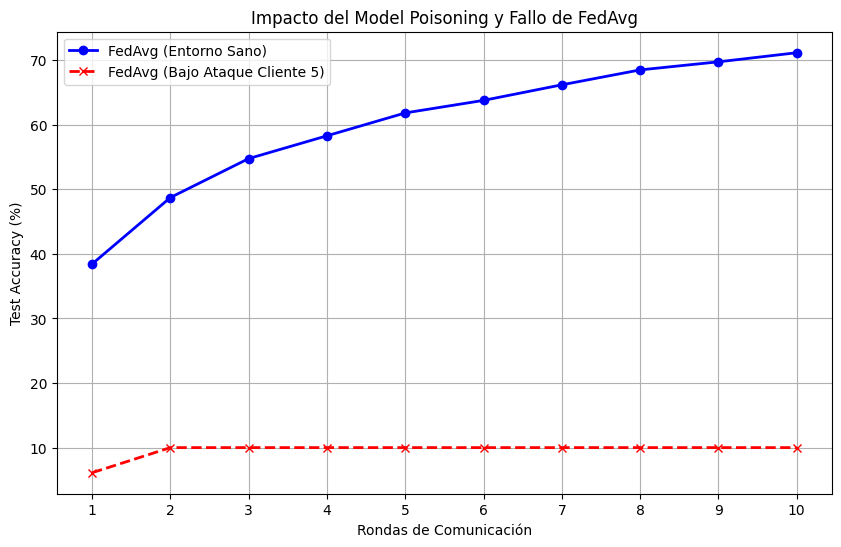

In [4]:
import matplotlib.pyplot as plt

# 1. Redefinimos el entrenamiento local para incluir el "botón" de ataque
def train_local_poisoned(model, train_loader, epochs=1, lr=0.01, is_malicious=False):
    model.train()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    
    for epoch in range(epochs):
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            #ATAQUE 1: Inversión de Etiquetas (Label Flipping)
            if is_malicious:
                labels = (labels + 1) % 10
                
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
    
    #ATAQUE 2: Escalamiento de Pesos (Weight Scaling)
    local_weights = copy.deepcopy(model.state_dict())
    if is_malicious:
        for key in local_weights.keys():
            local_weights[key] = local_weights[key] * 100.0
            
    return local_weights


# 2. Reiniciamos los modelos para una simulación limpia bajo ataque
global_model_poisoned = SimpleCNN().to(device)
local_models_poisoned = [SimpleCNN().to(device) for _ in range(num_clients)]
history_poisoned = []     

print("--- Iniciando entrenamiento federado BAJO ATAQUE ---")

for round_num in range(1, 11):
    local_weights_list = []
    global_weights = global_model_poisoned.state_dict()
    
    for i in range(num_clients):
        local_models_poisoned[i].load_state_dict(global_weights)
        
        # El cliente 5 (índice 4) es el nodo malicioso
        is_malicious = True if i == 4 else False
        
        weights = train_local_poisoned(local_models_poisoned[i], client_loaders[i], epochs=1, is_malicious=is_malicious)
        local_weights_list.append(weights)
    
    # Agregación (El servidor sigue usando FedAvg, creyendo que todos son buenos)
    new_global_weights = federated_averaging(local_weights_list)
    global_model_poisoned.load_state_dict(new_global_weights)
    
    # Evaluación
    accuracy = evaluate_model(global_model_poisoned, testloader)
    history_poisoned.append(accuracy)
    
    print(f"Ronda {round_num:02d} | Test Accuracy (Envenenado): {accuracy:.4f}%")

# 3. Generación de la gráfica comparativa
plt.figure(figsize=(10, 6))
# 'history' contiene los datos de tu celda anterior sana
plt.plot(range(1, 11), history, label='FedAvg (Entorno Sano)', marker='o', color='blue', linewidth=2)
# 'history_poisoned' contiene los datos del ataque
plt.plot(range(1, 11), history_poisoned, label='FedAvg (Bajo Ataque Cliente 5)', marker='x', color='red', linewidth=2, linestyle='--')

plt.title('Impacto del Model Poisoning y Fallo de FedAvg')
plt.xlabel('Rondas de Comunicación')
plt.ylabel('Test Accuracy (%)')
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.show()

In [5]:
def trimmed_mean(local_weights, trim_ratio=0.2):
    # trim_ratio 0.2 con 5 clientes significa descartar 1 por arriba y 1 por abajo
    avg_weights = copy.deepcopy(local_weights[0])
    num_clients = len(local_weights)
    trim_num = int(num_clients * trim_ratio) # 5 * 0.2 = 1
    
    for key in avg_weights.keys():
        # Apilamos los pesos de todos los clientes para este parámetro específico
        stacked_weights = torch.stack([local_weights[i][key] for i in range(num_clients)], dim=0)
        
        # Los ordenamos de menor a mayor
        sorted_weights, _ = torch.sort(stacked_weights, dim=0)
        
        # Cortamos los extremos (el 1 más bajo y el 1 más alto)
        if trim_num > 0:
            trimmed_weights = sorted_weights[trim_num : num_clients - trim_num]
            # Promediamos los 3 restantes
            avg_weights[key] = torch.mean(trimmed_weights, dim=0)
        else:
            avg_weights[key] = torch.mean(stacked_weights, dim=0)
            
    return avg_weights

--- Iniciando entrenamiento federado BAJO ATAQUE ---
Ronda 01 | Test Accuracy (Envenenado): 39.0300%
Ronda 02 | Test Accuracy (Envenenado): 47.2300%
Ronda 03 | Test Accuracy (Envenenado): 53.1100%
Ronda 04 | Test Accuracy (Envenenado): 57.8800%
Ronda 05 | Test Accuracy (Envenenado): 60.9400%
Ronda 06 | Test Accuracy (Envenenado): 64.2500%
Ronda 07 | Test Accuracy (Envenenado): 66.2600%
Ronda 08 | Test Accuracy (Envenenado): 67.6400%
Ronda 09 | Test Accuracy (Envenenado): 69.2700%
Ronda 10 | Test Accuracy (Envenenado): 70.4200%


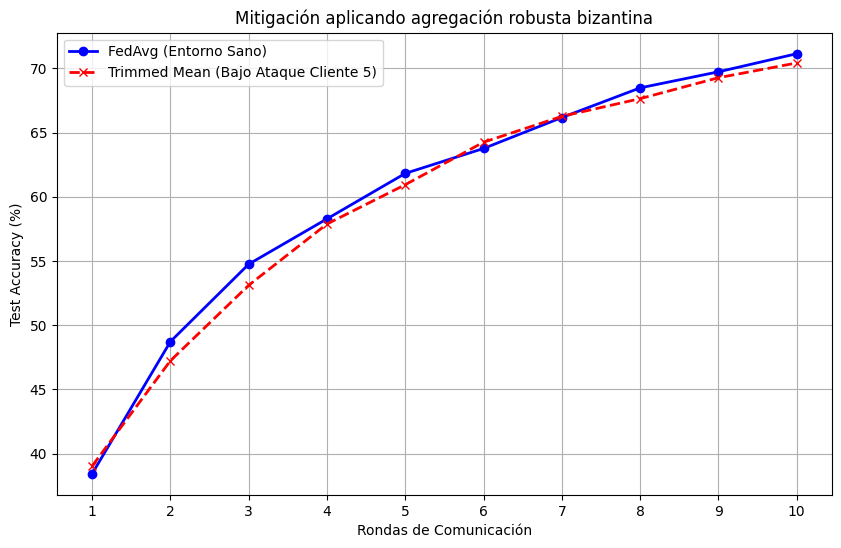

In [6]:
# 1. Redefinimos el entrenamiento local para incluir el "botón" de ataque
def train_local_poisoned(model, train_loader, epochs=1, lr=0.01, is_malicious=False):
    model.train()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    
    for epoch in range(epochs):
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            #ATAQUE 1: Inversión de Etiquetas (Label Flipping)
            if is_malicious:
                labels = (labels + 1) % 10
                
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
    
    #ATAQUE 2: Escalamiento de Pesos (Weight Scaling)
    local_weights = copy.deepcopy(model.state_dict())
    if is_malicious:
        for key in local_weights.keys():
            local_weights[key] = local_weights[key] * 100.0
            
    return local_weights


# 2. Reiniciamos los modelos para una simulación limpia bajo ataque
global_model_robust = SimpleCNN().to(device)
local_models_robust = [SimpleCNN().to(device) for _ in range(num_clients)]
history_robust = []     

print("--- Iniciando entrenamiento federado BAJO ATAQUE ---")

for round_num in range(1, 11):
    local_weights_list = []
    global_weights = global_model_robust.state_dict()
    
    for i in range(num_clients):
        local_models_robust[i].load_state_dict(global_weights)
        
        # El cliente 5 (índice 4) es el nodo malicioso
        is_malicious = True if i == 4 else False
        
        weights = train_local_poisoned(local_models_robust[i], client_loaders[i], epochs=1, is_malicious=is_malicious)
        local_weights_list.append(weights)
    
    # Agregación (El servidor sigue usando FedAvg, creyendo que todos son buenos)
    new_global_weights = trimmed_mean(local_weights_list)
    global_model_robust.load_state_dict(new_global_weights)
    
    # Evaluación
    accuracy = evaluate_model(global_model_robust, testloader)
    history_robust.append(accuracy)
    
    print(f"Ronda {round_num:02d} | Test Accuracy (Envenenado): {accuracy:.4f}%")

# 3. Generación de la gráfica comparativa
plt.figure(figsize=(10, 6))
# 'history' contiene los datos de tu celda anterior sana
plt.plot(range(1, 11), history, label='FedAvg (Entorno Sano)', marker='o', color='blue', linewidth=2)
# 'history_robust' contiene los datos del ataque
plt.plot(range(1, 11), history_robust, label='Trimmed Mean (Bajo Ataque Cliente 5)', marker='x', color='red', linewidth=2, linestyle='--')

plt.title('Mitigación aplicando agregación robusta bizantina')
plt.xlabel('Rondas de Comunicación')
plt.ylabel('Test Accuracy (%)')
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.show()